<a href="https://colab.research.google.com/github/isurushanaka/SLAAI2026-Preconference-Workshop/blob/main/SLAAI2026_Perconference_Workshop.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Medical Imaging Pipeline

<img src="https://raw.githubusercontent.com/isurushanaka/SLAAI2026-Preconference-Workshop/refs/heads/main/medical_imaging_pipeline_technologies.png"
     alt="Markdown Monster icon"
     style="float: left; margin-right: 10px;" />

# **Outline**

1.   Dataset
2.   Classical Enhancement
3.   Deep Learning Enhancement
4.   Generative AI Enhancement
5.   Classification (CNN)
6.   Segmentation (CNN)
7.   Foundation Model (Segmentation)


# **1. Dataset**

### Download the BRICS2025 Dataset

In [ ]:
import requests, zipfile

url = "https://data.mendeley.com/public-files/datasets/c7dj4pwhcv/files/fef9f6e9-8349-4cd9-8e06-ce0ea9f6236e/file_downloaded"
output_file = "dataset.zip"

response = requests.get(url, stream=True)
response.raise_for_status()

with open(output_file, "wb") as f:
    for chunk in response.iter_content(chunk_size=8192):
        f.write(chunk)

# Extract
with zipfile.ZipFile("dataset.zip", "r") as zip_ref:
    zip_ref.extractall("dataset")

print("BRISC2025 Dataset Downloaded")

BRISC2025 Dataset Downloaded


### Dataset Overview Statistics

In [ ]:
from pathlib import Path
import pandas as pd

root = Path("/content/dataset/brisc2025") #/content/dataset/brisc2025/classification_task/test

stats = []

for split in ["train", "test"]:
    for cls in ["glioma", "meningioma", "pituitary", "no_tumor"]:
        n = len(list((root/"classification_task"/split/cls).glob("*.jpg")))
        stats.append({"Split": split,"Class": cls,"Images": n})

df = pd.DataFrame(stats)

print(df)
print("\nTotal images:", df["Images"].sum())

   Split       Class  Images
0  train      glioma    1147
1  train  meningioma    1329
2  train   pituitary    1457
3  train    no_tumor    1067
4   test      glioma     254
5   test  meningioma     306
6   test   pituitary     300
7   test    no_tumor     140

Total images: 6000


Class Distribution

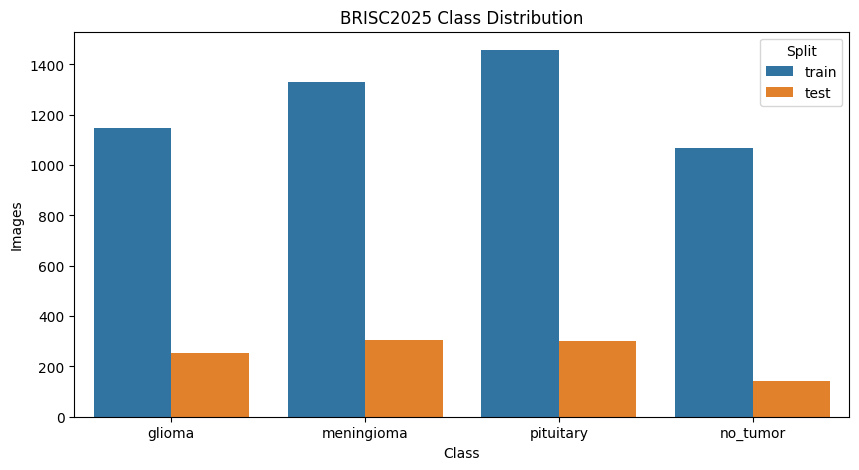

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
sns.barplot(data=df,x="Class",y="Images",hue="Split")
plt.title("BRISC2025 Class Distribution")
plt.show()

### Sample MRI Images

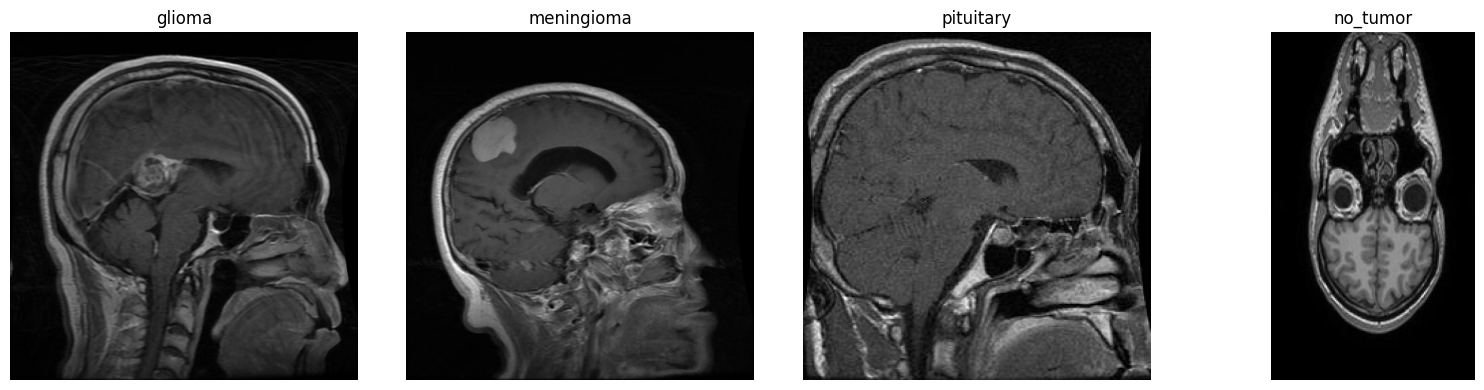

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import random

root = Path("/content/dataset/brisc2025") #/content/dataset/brisc2025/classification_task/test

classes = ["glioma","meningioma","pituitary","no_tumor"]

fig, axes = plt.subplots(1,4,figsize=(16,4))

for i, cls in enumerate(classes):
    files = list((root/"classification_task"/"train"/cls).glob("*.jpg"))
    img = Image.open(random.choice(files))
    axes[i].imshow(img, cmap='gray')
    axes[i].set_title(cls)
    axes[i].axis("off")

plt.tight_layout()
plt.show()

Tumor Segmentation Visualization

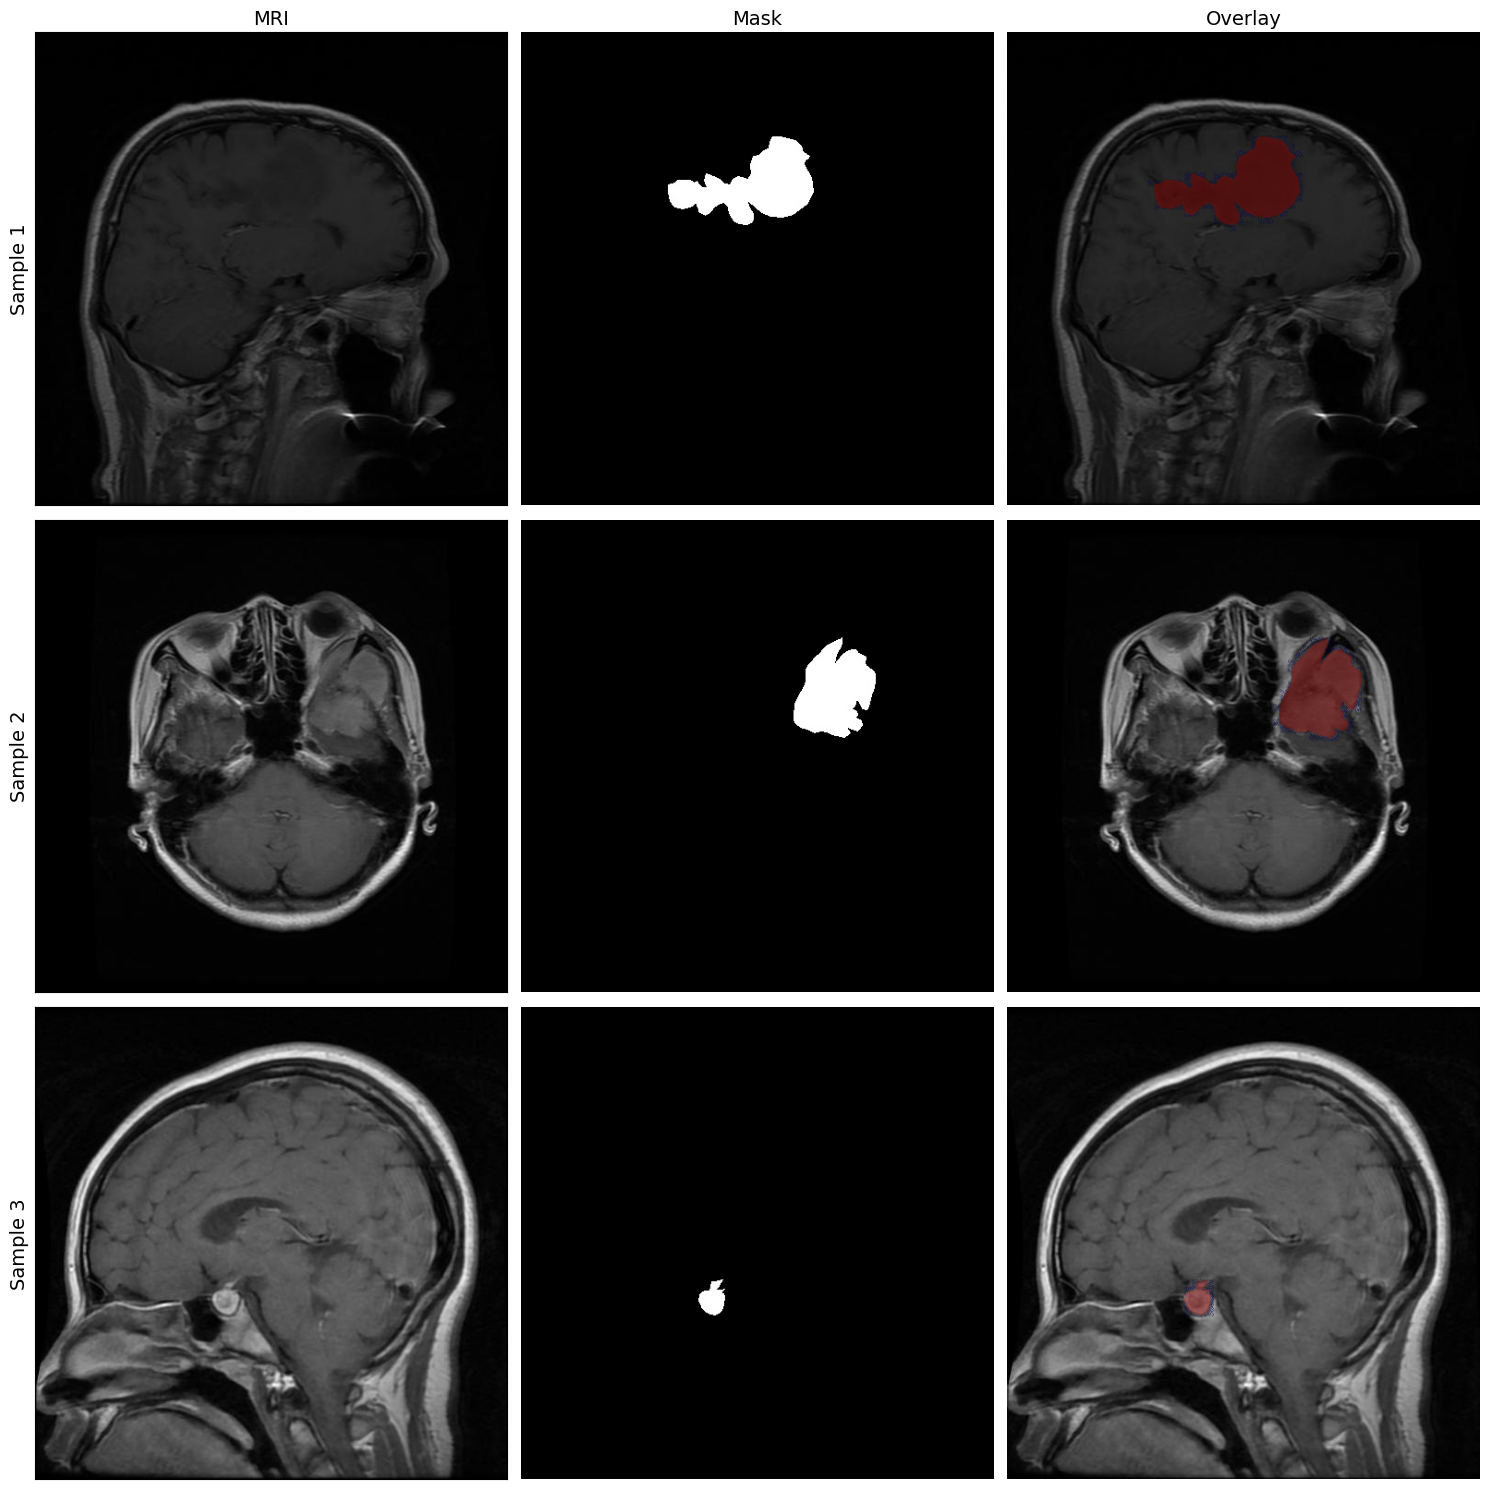

In [ ]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import random

# Find all image paths in the training segmentation set
segmentation_image_paths = list((root/"segmentation_task"/"train"/"images").glob("*.jpg"))

# Select 3 random samples
random.seed(42)
sample_segmentation_paths = random.sample(segmentation_image_paths, 3)

fig, axes = plt.subplots(3, 3, figsize=(15, 15))

for i, img_path in enumerate(sample_segmentation_paths):
    mask_path = root/"segmentation_task"/"train"/"masks"/(img_path.stem + ".png")

    img = np.array(Image.open(img_path))
    mask = np.array(Image.open(mask_path))

    # MRI Only
    axes[i, 0].imshow(img, cmap='gray')
    if i == 0:
        axes[i, 0].set_title("MRI", fontsize=14)
    axes[i, 0].set_ylabel(f"Sample {i+1}", fontsize=14)
    axes[i, 0].set_xticks([])
    axes[i, 0].set_yticks([])

    # Mask Only
    axes[i, 1].imshow(mask, cmap='gray')
    if i == 0:
        axes[i, 1].set_title("Mask", fontsize=14)
    axes[i, 1].axis("off")

    # Overlay
    axes[i, 2].imshow(img, cmap='gray')
    # Overlay the mask only where tumor exists to keep background clean
    masked_overlay = np.ma.masked_where(mask == 0, mask)
    axes[i, 2].imshow(masked_overlay, cmap='jet', alpha=0.5)
    if i == 0:
        axes[i, 2].set_title("Overlay", fontsize=14)
    axes[i, 2].axis("off")

plt.tight_layout()
plt.show()

Image Resolution Distribution

            Width       Height
count  3933.00000  3933.000000
mean    505.02924   505.628782
std      51.47811    50.003398
min     180.00000   202.000000
25%     512.00000   512.000000
50%     512.00000   512.000000
75%     512.00000   512.000000
max    1365.00000  1427.000000


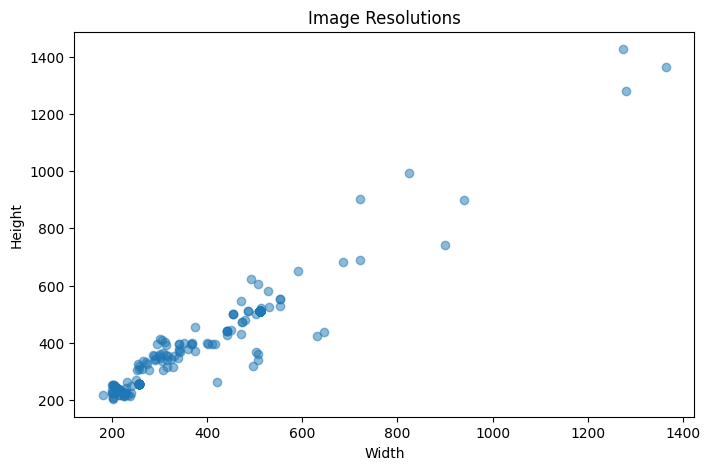

In [ ]:
from PIL import Image
import pandas as pd

records = []

image_dir = root/"segmentation_task"/"train"/"images"

for img_file in image_dir.glob("*.jpg"):
    img = Image.open(img_file)
    records.append([img.width,img.height])

res_df = pd.DataFrame(records,columns=["Width","Height"])

print(res_df.describe())

plt.figure(figsize=(8,5))
plt.scatter(res_df["Width"],res_df["Height"],alpha=0.5)

plt.xlabel("Width")
plt.ylabel("Height")
plt.title("Image Resolutions")
plt.show()

Tumor Size Distribution

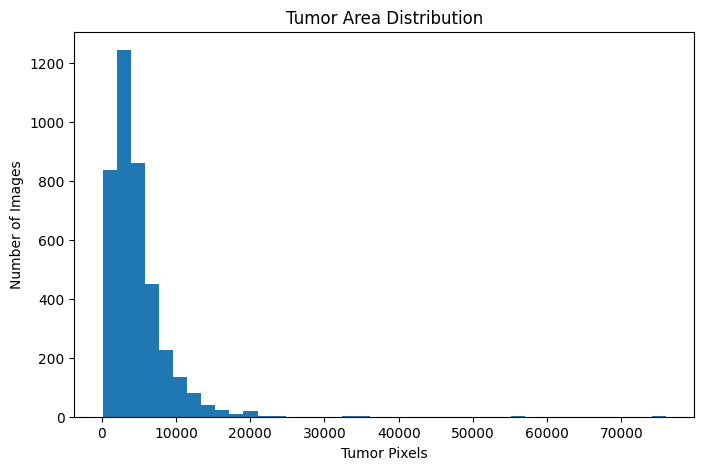

In [ ]:
import numpy as np
from PIL import Image

areas = []

mask_dir = root/"segmentation_task"/"train"/"masks"

for mask_file in mask_dir.glob("*.png"):
    mask = np.array(Image.open(mask_file))
    area = np.sum(mask > 0)
    areas.append(area)

plt.figure(figsize=(8,5))
plt.hist(areas, bins=40)
plt.xlabel("Tumor Pixels")
plt.ylabel("Number of Images")
plt.title("Tumor Area Distribution")

plt.show()

# **2. Classical Enhancement**

* Histogram Equalization (HE)
* CLAHE (Contrast Limited Adaptive Histogram Equalization)
* Gaussian Filtering
* Median Filtering
* Gaussian + CLAHE
* Median + CLAHE

<img src="https://raw.githubusercontent.com/isurushanaka/SLAAI2026-Preconference-Workshop/refs/heads/main/classical_enhancement_methods_overview.png"
     alt="Markdown Monster icon"
     style="float: left; margin-right: 10px;" />

Enhancement Functions

In [ ]:
import cv2
import numpy as np

def histogram_equalization(img):
    return cv2.equalizeHist(img)

def clahe_enhancement(img):
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    return clahe.apply(img)

def gaussian_filter(img):
    return cv2.GaussianBlur(img, (5,5), 0)

def median_filter(img):
    return cv2.medianBlur(img, 5)

def gaussian_clahe(img):
    blurred = gaussian_filter(img)
    return clahe_enhancement(blurred)

def median_clahe(img):
    filtered = median_filter(img)
    return clahe_enhancement(filtered)


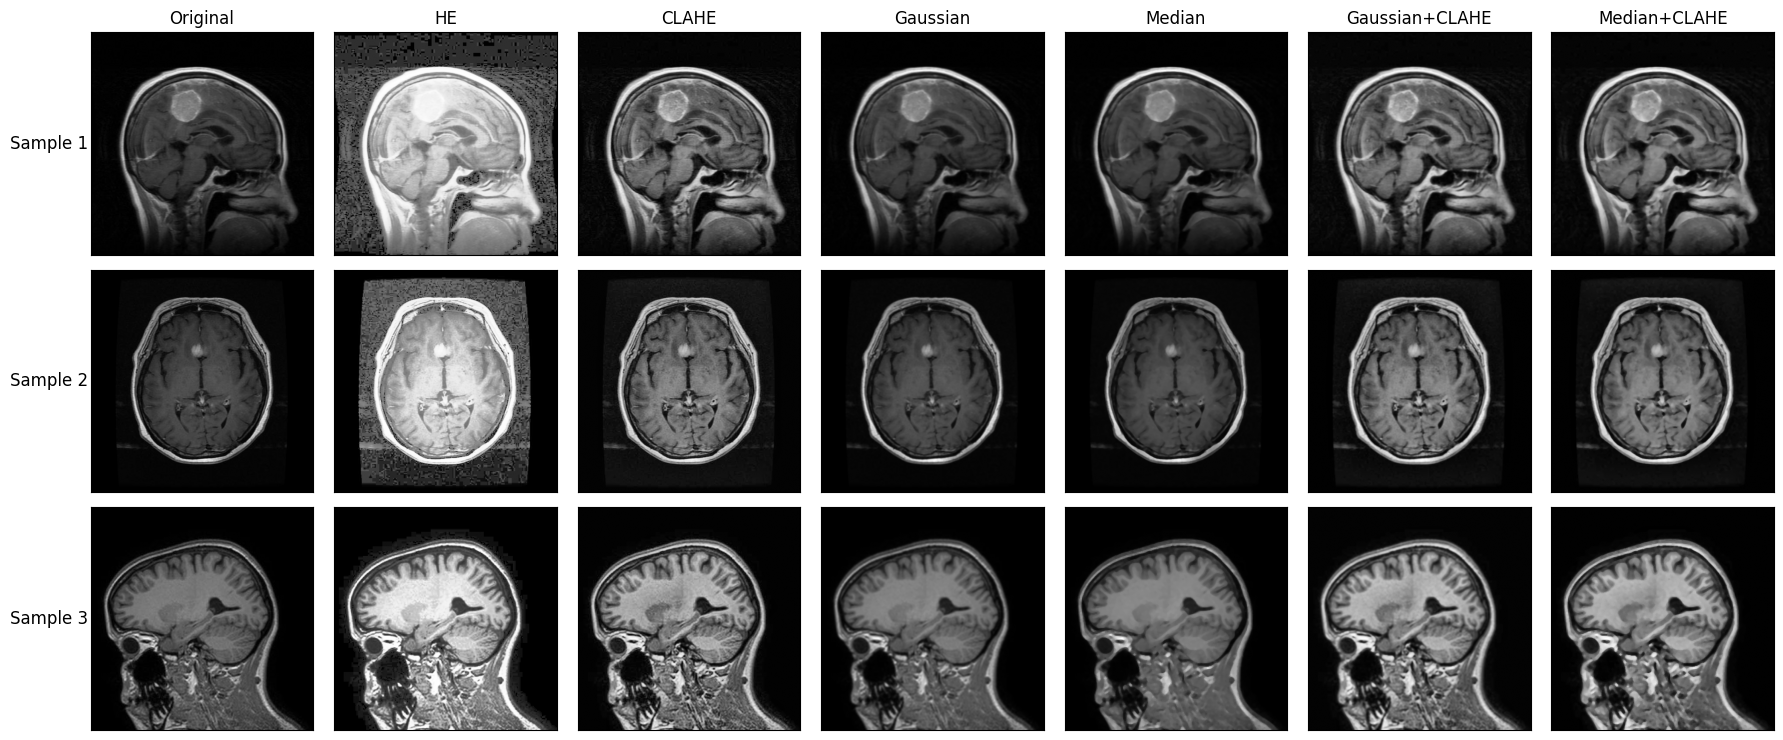

In [ ]:
import matplotlib.pyplot as plt
import cv2
import random
from pathlib import Path

# Find image paths
train_dir = Path("/content/dataset/brisc2025/classification_task/train")
all_image_paths = list(train_dir.rglob("*.jpg"))

# Select 3 random sample images
random.seed(42)  # For reproducibility
sample_paths = random.sample(all_image_paths, 3)

# Keep a reference image for the top-level 'img' and 'methods' dictionary
img_path = str(sample_paths[0])
img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

# Define the methods dictionary structure as requested
methods = {
    "Original": img,
    "HE": histogram_equalization(img),
    "CLAHE": clahe_enhancement(img),
    "Gaussian": gaussian_filter(img),
    "Median": median_filter(img),
    "Gaussian+CLAHE": gaussian_clahe(img),
    "Median+CLAHE": median_clahe(img)
}

# Define helper function to get enhanced dictionary for other samples
def get_enhanced_dict(image_path):
    img_gray = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
    return {
        "Original": img_gray,
        "HE": histogram_equalization(img_gray),
        "CLAHE": clahe_enhancement(img_gray),
        "Gaussian": gaussian_filter(img_gray),
        "Median": median_filter(img_gray),
        "Gaussian+CLAHE": gaussian_clahe(img_gray),
        "Median+CLAHE": median_clahe(img_gray)
    }

num_images = len(sample_paths)
num_methods = 7  # Original + 6 enhancement techniques

fig, axes = plt.subplots(num_images, num_methods, figsize=(18, 2.5 * num_images))

for i, img_p in enumerate(sample_paths):
    enhanced_methods = get_enhanced_dict(img_p)

    for j, (name, result) in enumerate(enhanced_methods.items()):
        ax = axes[i, j]
        ax.imshow(result, cmap='gray')
        if i == 0:
            ax.set_title(name, fontsize=12)
        if j == 0:
            ax.set_ylabel(f"Sample {i+1}", fontsize=12, rotation=0, labelpad=30, verticalalignment='center')
        ax.set_xticks([])
        ax.set_yticks([])

plt.tight_layout()
plt.show()

Image Quality Metrics

In [ ]:
from skimage.measure import shannon_entropy
from skimage.metrics import peak_signal_noise_ratio
from skimage.metrics import structural_similarity

def contrast(img):
    return np.std(img)

def entropy(img):
    return shannon_entropy(img)

def psnr(original, enhanced):
    return peak_signal_noise_ratio(
        original,
        enhanced,
        data_range=255
    )

def ssim(original, enhanced):
    return structural_similarity(original, enhanced, data_range=255)

In [ ]:
import pandas as pd

results = []

for method_name, enhanced in methods.items():
    results.append([method_name, contrast(enhanced), entropy(enhanced), psnr(img, enhanced), ssim(img, enhanced)])

df = pd.DataFrame(results, columns=["Method","Contrast ↑","Entropy ↑","PSNR ↑", "SSIM ↑"])
df.sort_index()

/usr/local/lib/python3.13/dist-packages/skimage/metrics/simple_metrics.py:168: RuntimeWarning: divide by zero encountered in scalar divide
  return 10 * np.log10((data_range**2) / err)


,Method,Contrast ↑,Entropy ↑,PSNR ↑,SSIM ↑
0,Original,40.683349,5.923381,inf,1.000000
1,HE,72.525488,5.711128,8.076632,0.266429
2,CLAHE,56.836945,6.623417,18.135688,0.617085
3,Gaussian,40.017495,5.881861,40.432037,0.983662
4,Median,40.159059,5.851258,39.780528,0.971088
5,Gaussian+CLAHE,55.829826,6.594740,18.457282,0.641431
6,Median+CLAHE,55.397230,6.588315,18.688806,0.647177


# **3. Deep Learning-Based Enhancement**

In [ ]:
def add_noise(img, mean=0, std=20):
    noise = np.random.normal(mean, std, img.shape)
    noisy = img.astype(np.float32) + noise
    noisy = np.clip(noisy, 0, 255)

    return noisy.astype(np.uint8)

In [ ]:
import cv2

image_paths = list(Path("/content/dataset/brisc2025/classification_task/test").rglob("*.jpg"))

X = []
Y = []

for path in image_paths:

    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (128,128))
    noisy = add_noise(img)
    X.append(noisy/255.0)
    Y.append(img/255.0)

X = np.array(X)[...,None]
Y = np.array(Y)[...,None]

print(X.shape)

(1000, 128, 128, 1)


Denoising Autoencoder

<img src="https://raw.githubusercontent.com/isurushanaka/SLAAI2026-Preconference-Workshop/refs/heads/main/autoencoder_architecture.png"
     alt="Markdown Monster icon"
     style="float: left; margin-right: 10px;" />

In [ ]:
from google.colab import drive
import os
from tensorflow.keras.layers import *
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam


# Mount Google Drive
drive.mount('/content/drive')

inputs = Input((128,128,1))

# Encoder
x = Conv2D(32,3,activation='relu',padding='same')(inputs)
x = MaxPooling2D((2,2))(x)

x = Conv2D(64,3,activation='relu',padding='same')(x)
x = MaxPooling2D((2,2))(x)

x = Conv2D(128,3,activation='relu',padding='same')(x)
encoded = MaxPooling2D((2,2))(x)

# Decoder
x = Conv2D(128,3,activation='relu',padding='same')(encoded)
x = UpSampling2D((2,2))(x)

x = Conv2D(64,3,activation='relu',padding='same')(x)
x = UpSampling2D((2,2))(x)

x = Conv2D(32,3,activation='relu',padding='same')(x)
x = UpSampling2D((2,2))(x)

outputs = Conv2D(1,3,activation='sigmoid',padding='same')(x)

AutoEncoder = Model(inputs, outputs)
AutoEncoder.compile(optimizer=Adam(learning_rate=1e-3), loss='binary_crossentropy')
AutoEncoder.summary()

history = AutoEncoder.fit(X,Y,epochs=128,batch_size=4,validation_split=0.2)

# Save the model to Google Drive
save_dir = '/content/drive/MyDrive/BRISC2025_Models'
os.makedirs(save_dir, exist_ok=True)
model_path = os.path.join(save_dir, 'denoising_autoencoder.keras')
AutoEncoder.save(model_path)
print(f"Model successfully saved to {model_path}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_42 (Conv2D)              │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_43 (Conv2D)              │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_44 (Conv2D)              │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_45 (Conv2D)              │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_18 (UpSampling2D) │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_46 (Conv2D)              │ (None, 32, 32, 64)     │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_19 (UpSampling2D) │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_47 (Conv2D)              │ (None, 64, 64, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_20 (UpSampling2D) │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_48 (Conv2D)              │ (None, 128, 128, 1)    │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 332,801 (1.27 MB)

 Trainable params: 332,801 (1.27 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/128
200/200 ━━━━━━━━━━━━━━━━━━━━ 18s 28ms/step - loss: 0.3855 - val_loss: 0.4029
Epoch 2/128
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.3468 - val_loss: 0.3970
Epoch 3/128
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.3436 - val_loss: 0.3953
Epoch 4/128
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.3419 - val_loss: 0.3945
Epoch 5/128
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.3409 - val_loss: 0.3936
Epoch 6/128
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.3403 - val_loss: 0.3937
Epoch 7/128
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.3403 - val_loss: 0.3929
Epoch 8/128
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.3398 - val_loss: 0.3930
Epoch 9/128
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.3394 - val_loss: 0.3920
Epoch 10/128
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.3390 - val_loss: 0.3921
Epoch 11/128
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.3385 - val_loss: 0.3915
Epoch 12/128
200/200 ━━━━━━━━━━━━━━━━━━

Loading model from /content/drive/MyDrive/BRISC2025_Models/denoising_autoencoder.keras...
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 518ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step


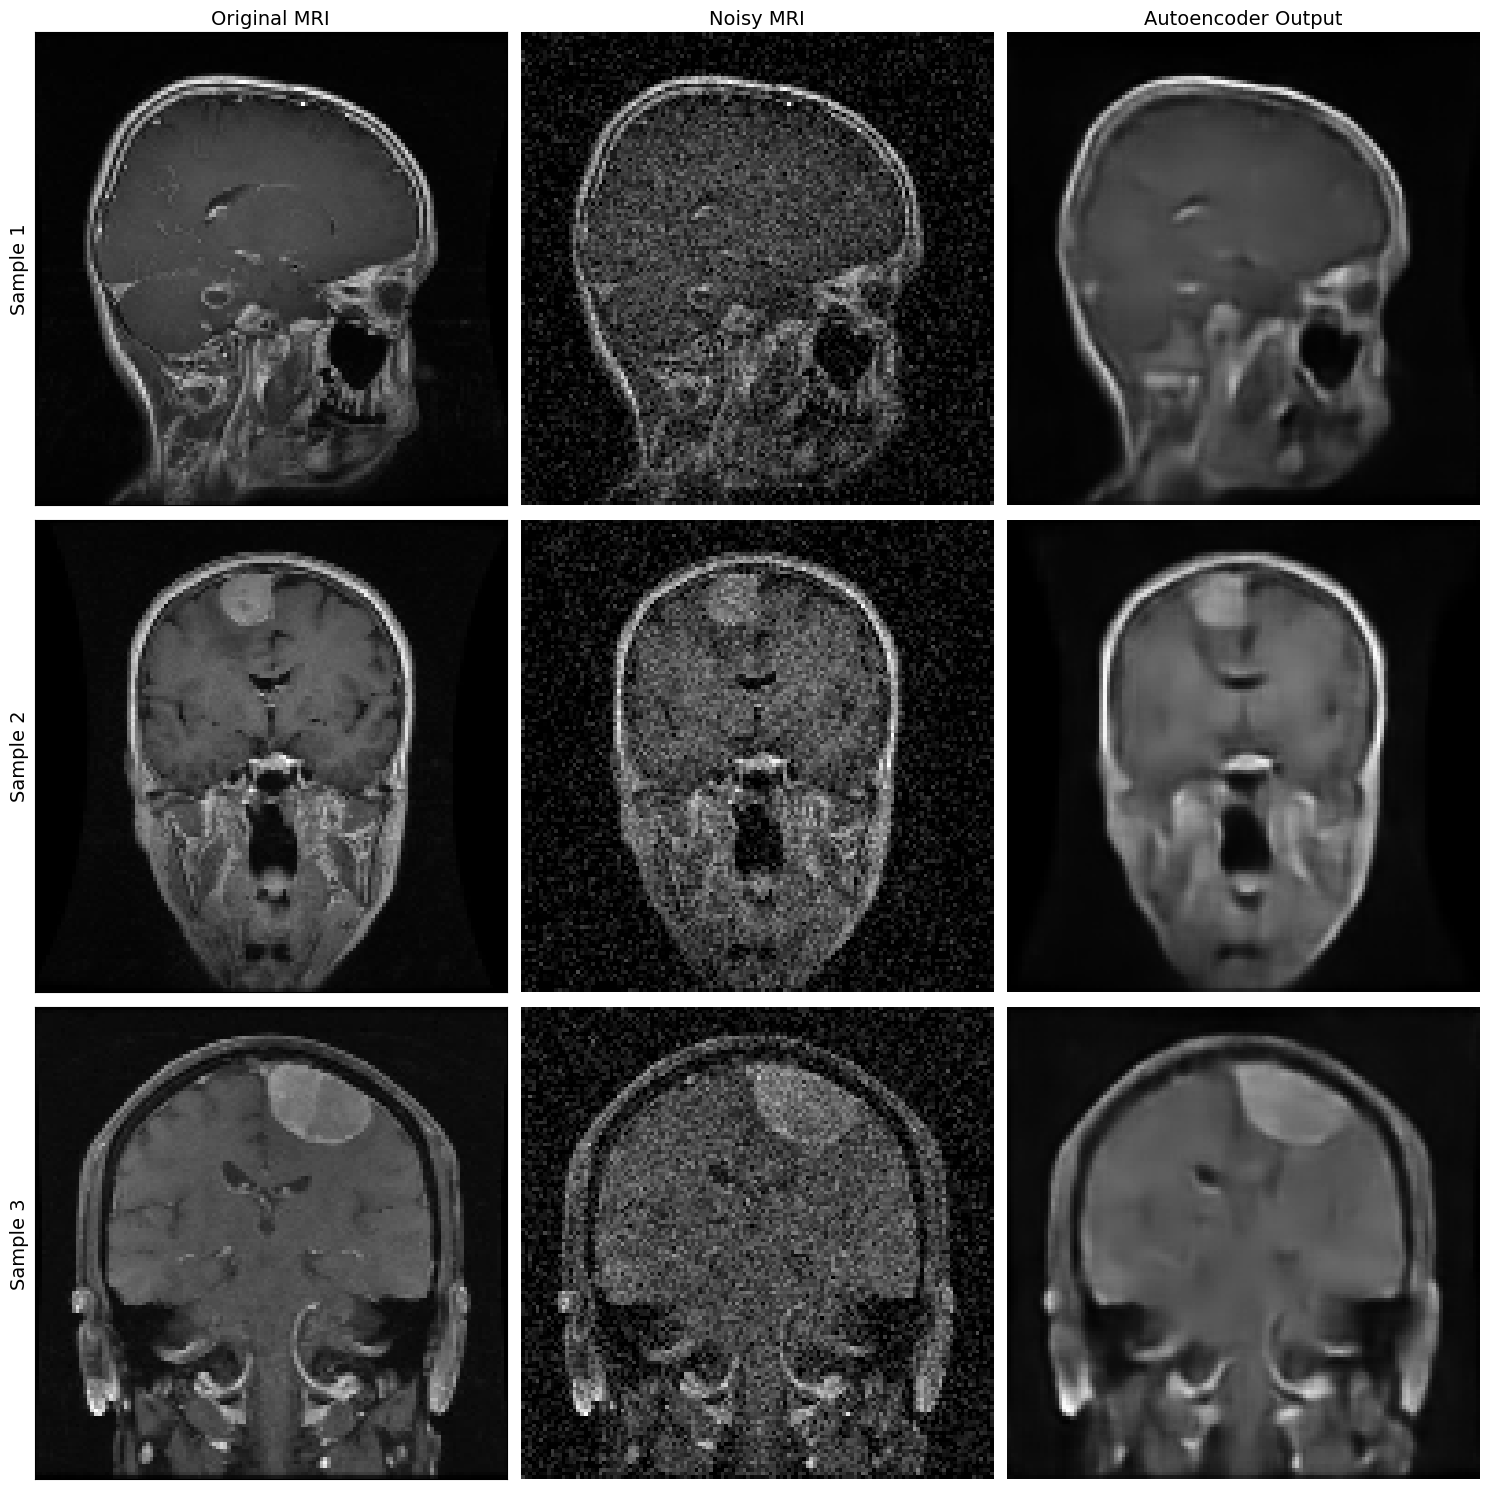

In [ ]:
import matplotlib.pyplot as plt
import random
import os
from tensorflow.keras.models import load_model

# Path to the saved model on Google Drive
model_path = '/content/drive/MyDrive/BRISC2025_Models/denoising_autoencoder.keras'

# Load the model
if os.path.exists(model_path):
    print(f"Loading model from {model_path}...")
    loaded_AutoEncoder = load_model(model_path)
else:
    print(f"Saved model not found at {model_path}. Falling back to active variable AutoEncoder.")
    loaded_AutoEncoder = AutoEncoder

# Select 3 random indices from the dataset
random.seed(42)
sample_indices = random.sample(range(len(X)), 3)

fig, axes = plt.subplots(3, 3, figsize=(15, 15))

for i, idx in enumerate(sample_indices):
    clean = Y[idx, :, :, 0]
    noisy = X[idx, :, :, 0]
    pred = loaded_AutoEncoder.predict(X[idx:idx+1])[0, :, :, 0]

    # Original
    axes[i, 0].imshow(clean, cmap='gray')
    if i == 0:
        axes[i, 0].set_title("Original MRI", fontsize=14)
    axes[i, 0].set_ylabel(f"Sample {i+1}", fontsize=14)
    axes[i, 0].set_xticks([])
    axes[i, 0].set_yticks([])

    # Noisy
    axes[i, 1].imshow(noisy, cmap='gray')
    if i == 0:
        axes[i, 1].set_title("Noisy MRI", fontsize=14)
    axes[i, 1].axis("off")

    # Autoencoder Output
    axes[i, 2].imshow(pred, cmap='gray')
    if i == 0:
        axes[i, 2].set_title("Autoencoder Output", fontsize=14)
    axes[i, 2].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
idx = 10
noisy_img = X[idx,:,:,0]
clean_img = Y[idx,:,:,0]

enhanced_dl = AutoEncoder.predict(X[idx:idx+1])[0,:,:,0]

methods = {
        "Original": clean_img,
        "Noisy": noisy_img,
        "AutoEncoder Enhanced": enhanced_dl,
    }

results = []

# Calculate metrics for classical methods, resizing them from 512x512 to 128x128
for method_name, enhanced in methods.items():
    enhanced = cv2.resize(enhanced, (128, 128))
    results.append([
        method_name,
        contrast(enhanced),
        entropy(enhanced),
        psnr(img, enhanced),
        ssim(img, enhanced)
    ])

# Display the results in a DataFrame
df_comparison = pd.DataFrame(results, columns=["Method", "Contrast ↑", "Entropy ↑", "PSNR ↑", "SSIM ↑"])
df_comparison.sort_index()

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 538ms/step


,Method,Contrast ↑,Entropy ↑,PSNR ↑,SSIM ↑
0,Original,0.172474,5.068204,12.803619,0.042665
1,Noisy,0.171469,5.890000,12.804619,0.044326
2,AutoEncoder Enhanced,0.168813,13.999146,12.803566,0.042660


# **4. Generative AI-Based Enhancement**



<img src="https://raw.githubusercontent.com/isurushanaka/SLAAI2026-Preconference-Workshop/refs/heads/main/GAN-Training.png"
     alt="Markdown Monster icon"
     style="float: left; margin-right: 10px;" />

Generator Network

<img src="https://raw.githubusercontent.com/isurushanaka/SLAAI2026-Preconference-Workshop/refs/heads/main/unet_generator_architecture.png"
     alt="Markdown Monster icon"
     style="float: left; margin-right: 10px;" />

Discriminator Network

<img src="https://raw.githubusercontent.com/isurushanaka/SLAAI2026-Preconference-Workshop/refs/heads/main/patchgan_discriminator_architecture.png"
     style="float: left; margin-right: 10px;" />

In [ ]:
import tensorflow as tf
from tensorflow.keras.layers import *
from tensorflow.keras.models import Model
import numpy as np

def build_generator():
    inputs = Input((128, 128, 1))

    # Downsampling (Encoder)
    d1 = Conv2D(64, 4, strides=2, padding='same', activation='relu')(inputs)
    d2 = Conv2D(128, 4, strides=2, padding='same', use_bias=False)(d1)
    d2 = BatchNormalization()(d2)
    d2 = ReLU()(d2)

    d3 = Conv2D(256, 4, strides=2, padding='same', use_bias=False)(d2)
    d3 = BatchNormalization()(d3)
    d3 = ReLU()(d3)

    # Bottleneck
    b = Conv2D(512, 4, strides=2, padding='same', use_bias=False)(d3)
    b = BatchNormalization()(b)
    b = ReLU()(b)

    # Upsampling (Decoder with Skip Connections)
    u1 = Conv2DTranspose(256, 4, strides=2, padding='same', use_bias=False)(b)
    u1 = BatchNormalization()(u1)
    u1 = Dropout(0.5)(u1)
    u1 = Concatenate()([u1, d3])
    u1 = ReLU()(u1)

    u2 = Conv2DTranspose(128, 4, strides=2, padding='same', use_bias=False)(u1)
    u2 = BatchNormalization()(u2)
    u2 = Concatenate()([u2, d2])
    u2 = ReLU()(u2)

    u3 = Conv2DTranspose(64, 4, strides=2, padding='same', use_bias=False)(u2)
    u3 = BatchNormalization()(u3)
    u3 = Concatenate()([u3, d1])
    u3 = ReLU()(u3)

    outputs = Conv2DTranspose(1, 4, strides=2, padding='same', activation='sigmoid')(u3)

    return Model(inputs, outputs, name="UNet_Generator")

def build_discriminator():
    # Conditioned on both the input noisy image and the target (or generated) image
    src_image_input = Input(shape=(128, 128, 1))
    target_image_input = Input(shape=(128, 128, 1))

    merged = Concatenate()([src_image_input, target_image_input])

    d1 = Conv2D(64, 4, strides=2, padding='same', activation='relu')(merged)
    d2 = Conv2D(128, 4, strides=2, padding='same', use_bias=False)(d1)
    d2 = BatchNormalization()(d2)
    d2 = ReLU()(d2)

    d3 = Conv2D(256, 4, strides=2, padding='same', use_bias=False)(d2)
    d3 = BatchNormalization()(d3)
    d3 = ReLU()(d3)

    outputs = Conv2D(1, 4, padding='same', activation='sigmoid')(d3)

    return Model([src_image_input, target_image_input], outputs, name="PatchGAN_Discriminator")

generator = build_generator()
discriminator = build_discriminator()

In [ ]:
generator.summary()

Model: "UNet_Generator"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_18 (Conv2D)  │ (None, 64, 64,    │      1,088 │ input_layer_5[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 32, 32,    │    131,072 │ conv2d_18[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        512 │ conv2d_19[0][0]   │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_8 (ReLU)      │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_20 (Conv2D)  │ (None, 16, 16,    │    524,288 │ re_lu_8[0][0]     │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │      1,024 │ conv2d_20[0][0]   │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_9 (ReLU)      │ (None, 16, 16,    │          0 │ batch_normalizat… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 8, 8, 512) │  2,097,152 │ re_lu_9[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 8, 8, 512) │      2,048 │ conv2d_21[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_10 (ReLU)     │ (None, 8, 8, 512) │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_4  │ (None, 16, 16,    │  2,097,152 │ re_lu_10[0][0]    │
│ (Conv2DTranspose)   │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │      1,024 │ conv2d_transpose… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 16, 16,    │          0 │ batch_normalizat… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_4       │ (None, 16, 16,    │          0 │ dropout_1[0][0],  │
│ (Concatenate)       │ 512)              │            │ re_lu_9[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_11 (ReLU)     │ (None, 16, 16,    │          0 │ concatenate_4[0]… │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_5  │ (None, 32, 32,    │  1,048,576 │ re_lu_11[0][0]    │
│ (Conv2DTranspose)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 6,168,897 (23.53 MB)

 Trainable params: 6,166,209 (23.52 MB)

 Non-trainable params: 2,688 (10.50 KB)

In [ ]:
discriminator.summary()

Model: "PatchGAN_Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_6       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_7       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_7       │ (None, 128, 128,  │          0 │ input_layer_6[0]… │
│ (Concatenate)       │ 2)                │            │ input_layer_7[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_22 (Conv2D)  │ (None, 64, 64,    │      2,112 │ concatenate_7[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_23 (Conv2D)  │ (None, 32, 32,    │    131,072 │ conv2d_22[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        512 │ conv2d_23[0][0]   │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_14 (ReLU)     │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_24 (Conv2D)  │ (None, 16, 16,    │    524,288 │ re_lu_14[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │      1,024 │ conv2d_24[0][0]   │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_15 (ReLU)     │ (None, 16, 16,    │          0 │ batch_normalizat… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_25 (Conv2D)  │ (None, 16, 16, 1) │      4,097 │ re_lu_15[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 663,105 (2.53 MB)

 Trainable params: 662,337 (2.53 MB)

 Non-trainable params: 768 (3.00 KB)

In [ ]:
import tensorflow as tf

# Optimizers
generator_optimizer = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)
discriminator_optimizer = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)

# Loss objects
loss_object = tf.keras.losses.BinaryCrossentropy(from_logits=False)

def generator_loss(disc_generated_output, gen_output, target):
    # Adversarial Loss
    gan_loss = loss_object(tf.ones_like(disc_generated_output), disc_generated_output)
    # L1 Loss for pixel-level correctness
    l1_loss = tf.reduce_mean(tf.abs(target - gen_output))
    # Total loss
    total_gen_loss = gan_loss + (100 * l1_loss)
    return total_gen_loss, gan_loss, l1_loss

def discriminator_loss(disc_real_output, disc_generated_output):
    real_loss = loss_object(tf.ones_like(disc_real_output), disc_real_output)
    generated_loss = loss_object(tf.zeros_like(disc_generated_output), disc_generated_output)
    total_disc_loss = real_loss + generated_loss
    return total_disc_loss

In [ ]:
@tf.function
def train_step(input_image, target_image):
    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        gen_output = generator(input_image, training=True)

        disc_real_output = discriminator([input_image, target_image], training=True)
        disc_generated_output = discriminator([input_image, gen_output], training=True)

        gen_total_loss, gen_gan_loss, gen_l1_loss = generator_loss(disc_generated_output, gen_output, target_image)
        disc_loss = discriminator_loss(disc_real_output, disc_generated_output)

    generator_gradients = gen_tape.gradient(gen_total_loss, generator.trainable_variables)
    discriminator_gradients = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

    generator_optimizer.apply_gradients(zip(generator_gradients, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(discriminator_gradients, discriminator.trainable_variables))

    return gen_total_loss, disc_loss

In [ ]:
import os

epochs = 128
batch_size = 16
num_samples = X.shape[0]

# Lists to store the actual average training losses for plotting
gen_losses_history = []
disc_losses_history = []

print("Starting training loop...")
for epoch in range(epochs):
    # Shuffle dataset at each epoch
    indices = np.arange(num_samples)
    np.random.shuffle(indices)
    shuffled_X = X[indices]
    shuffled_Y = Y[indices]

    epoch_gen_loss = 0.0
    epoch_disc_loss = 0.0
    steps = num_samples // batch_size

    for step in range(steps):
        start_idx = step * batch_size
        end_idx = start_idx + batch_size

        input_batch = tf.cast(shuffled_X[start_idx:end_idx], tf.float32)
        target_batch = tf.cast(shuffled_Y[start_idx:end_idx], tf.float32)

        g_loss, d_loss = train_step(input_batch, target_batch)
        epoch_gen_loss += g_loss
        epoch_disc_loss += d_loss

    # Calculate average loss for this epoch
    avg_gen_loss = (epoch_gen_loss / steps).numpy() if hasattr(epoch_gen_loss, 'numpy') else (epoch_gen_loss / steps)
    avg_disc_loss = (epoch_disc_loss / steps).numpy() if hasattr(epoch_disc_loss, 'numpy') else (epoch_disc_loss / steps)

    # Store the actual metrics
    gen_losses_history.append(avg_gen_loss)
    disc_losses_history.append(avg_disc_loss)

    print(f"--> Epoch {epoch+1}/{epochs} Complete | Avg Gen Loss: {avg_gen_loss:.4f} | Avg Disc Loss: {avg_disc_loss:.4f}\n")

Save both Generator and Discriminator models to Google Drive
save_dir = '/content/drive/MyDrive/BRISC2025_Models'
os.makedirs(save_dir, exist_ok=True)

generator_path = os.path.join(save_dir, 'gan_generator.keras')
discriminator_path = os.path.join(save_dir, 'gan_discriminator.keras')

generator.save(generator_path)
discriminator.save(discriminator_path)

print(f"Generator successfully saved to {generator_path}")
print(f"Discriminator successfully saved to {discriminator_path}")

Starting training loop...
--> Epoch 1/10 Complete | Avg Gen Loss: 3.9309 | Avg Disc Loss: 0.9571

--> Epoch 2/10 Complete | Avg Gen Loss: 3.9514 | Avg Disc Loss: 0.9116

--> Epoch 3/10 Complete | Avg Gen Loss: 3.8493 | Avg Disc Loss: 0.9791

--> Epoch 4/10 Complete | Avg Gen Loss: 3.9020 | Avg Disc Loss: 0.8909

--> Epoch 5/10 Complete | Avg Gen Loss: 4.1774 | Avg Disc Loss: 0.8017

--> Epoch 6/10 Complete | Avg Gen Loss: 4.0047 | Avg Disc Loss: 0.9196

--> Epoch 7/10 Complete | Avg Gen Loss: 3.9586 | Avg Disc Loss: 0.9476

--> Epoch 8/10 Complete | Avg Gen Loss: 4.0002 | Avg Disc Loss: 0.8949

--> Epoch 9/10 Complete | Avg Gen Loss: 3.9991 | Avg Disc Loss: 0.9132

--> Epoch 10/10 Complete | Avg Gen Loss: 3.8809 | Avg Disc Loss: 0.9754



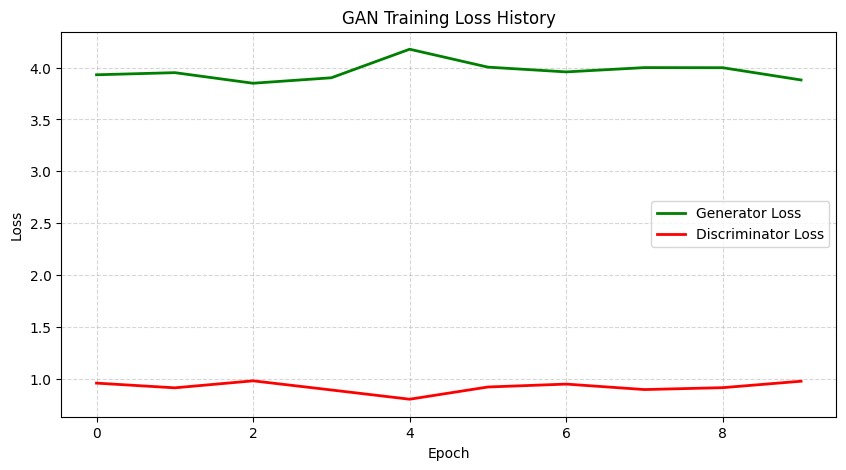

In [ ]:
import matplotlib.pyplot as plt

def plot_gan_loss(gen_losses, disc_losses):
    plt.figure(figsize=(10, 5))
    plt.plot(gen_losses, label='Generator Loss', color='g', linewidth=2)
    plt.plot(disc_losses, label='Discriminator Loss', color='r', linewidth=2)
    plt.title('GAN Training Loss History')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend()
    plt.show()

# Call the plot function with the actual training history we just gathered
# (Make sure to run the training cell above first to populate these variables!)
if 'gen_losses_history' in globals() and len(gen_losses_history) > 0:
    plot_gan_loss(gen_losses_history, disc_losses_history)
else:
    print("Please run the modified training loop cell above to populate gen_losses_history and disc_losses_history.")

Loading generator model from /content/drive/MyDrive/BRISC2025_Models/gan_generator.keras...
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 613ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step


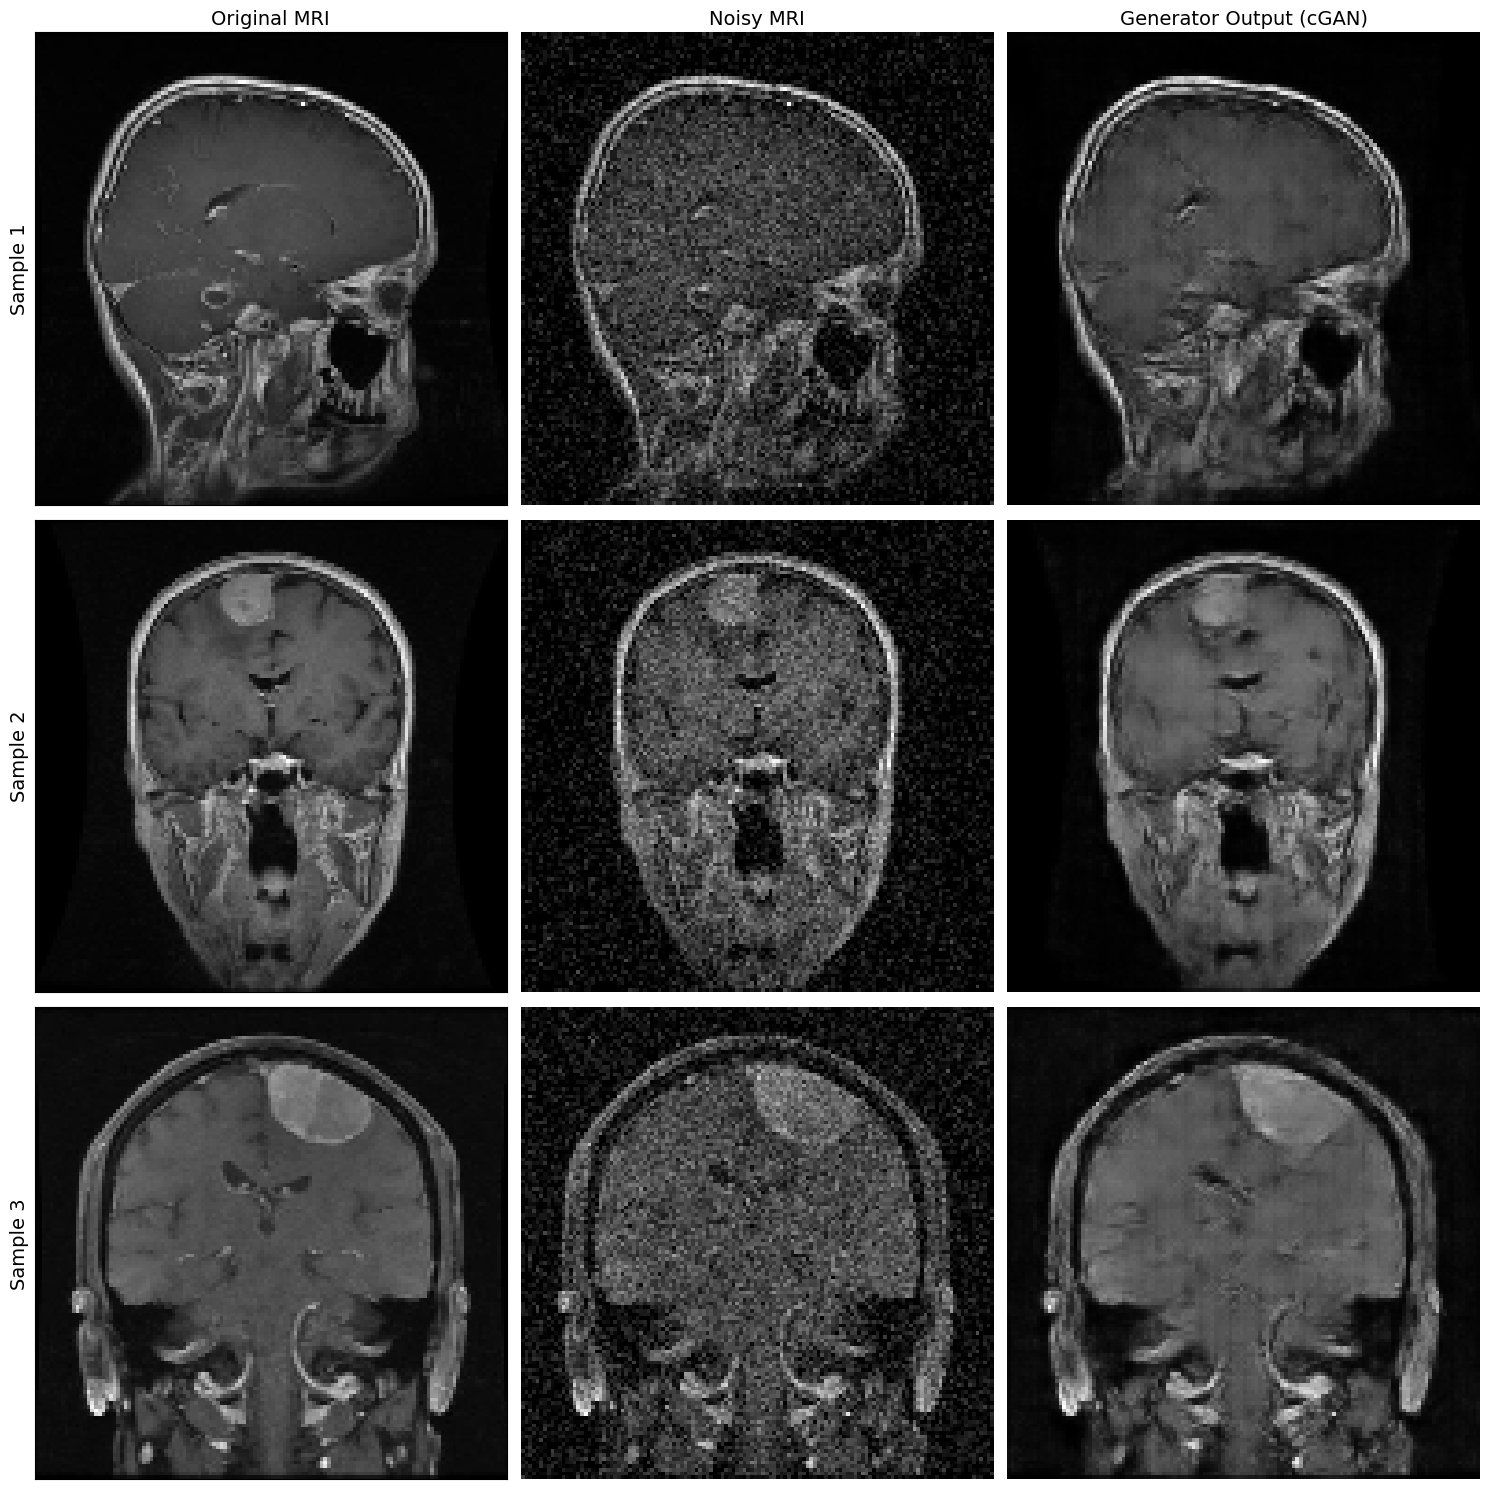

In [ ]:
import matplotlib.pyplot as plt
import random
import os
from tensorflow.keras.models import load_model

# Path to the saved generator weights
gen_model_path = '/content/drive/MyDrive/BRISC2025_Models/gan_generator.keras'

# Load the saved generator
if os.path.exists(gen_model_path):
    print(f"Loading generator model from {gen_model_path}...")
    loaded_generator = load_model(gen_model_path)
else:
    print(f"Saved generator model not found at {gen_model_path}. Falling back to the active 'generator' variable.")
    loaded_generator = generator

# Select 3 random indices
random.seed(42)
sample_indices = random.sample(range(len(X)), 3)

fig, axes = plt.subplots(3, 3, figsize=(15, 15))

for i, idx in enumerate(sample_indices):
    clean = Y[idx, :, :, 0]
    noisy = X[idx, :, :, 0]
    pred = loaded_generator.predict(X[idx:idx+1])[0, :, :, 0]

    # Original
    axes[i, 0].imshow(clean, cmap='gray')
    if i == 0:
        axes[i, 0].set_title("Original MRI", fontsize=14)
    axes[i, 0].set_ylabel(f"Sample {i+1}", fontsize=14)
    axes[i, 0].set_xticks([])
    axes[i, 0].set_yticks([])

    # Noisy
    axes[i, 1].imshow(noisy, cmap='gray')
    if i == 0:
        axes[i, 1].set_title("Noisy MRI", fontsize=14)
    axes[i, 1].axis("off")

    # Generator Output
    axes[i, 2].imshow(pred, cmap='gray')
    if i == 0:
        axes[i, 2].set_title("Generator Output (cGAN)", fontsize=14)
    axes[i, 2].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import cv2
import pandas as pd

idx = 10
noisy_img = X[idx, :, :, 0]
clean_img = Y[idx, :, :, 0]

# Predict using the loaded GAN generator
enhanced_gan = loaded_generator.predict(X[idx:idx+1])[0, :, :, 0]
enhanced_dl = AutoEncoder.predict(X[idx:idx+1])[0, :, :, 0]

methods_with_gan = {
    "Original": clean_img,
    "Noisy": noisy_img,
    "AutoEncoder Enhanced": enhanced_dl,
    "cGAN Enhanced": enhanced_gan
}

gan_results = []

for method_name, enhanced in methods_with_gan.items():
    # Resize to match standard image (img) dimensions
    enhanced_resized = cv2.resize(enhanced, (128, 128))
    gan_results.append([
        method_name,
        contrast(enhanced_resized),
        entropy(enhanced_resized),
        psnr(img, enhanced_resized),
        ssim(img, enhanced_resized)
    ])

df_gan_comparison = pd.DataFrame(gan_results, columns=["Method", "Contrast ↑", "Entropy ↑", "PSNR ↑", "SSIM ↑"])
display(df_gan_comparison)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step


,Method,Contrast ↑,Entropy ↑,PSNR ↑,SSIM ↑
0,Original,0.172474,5.068204,12.803619,0.042665
1,Noisy,0.171469,5.890000,12.804619,0.044326
2,AutoEncoder Enhanced,0.168813,13.999146,12.803566,0.042660
3,cGAN Enhanced,0.164191,13.999146,12.801979,0.042511


# **5. Classification (CNN)**

In [ ]:
import cv2
import numpy as np
import os
from pathlib import Path
import tensorflow as tf
from tensorflow.keras.layers import *
from tensorflow.keras.models import Sequential
from tensorflow.keras.utils import to_categorical

# Load and Preprocess Classification Dataset
root_dir = Path("/content/dataset/brisc2025/classification_task")
classes = ["glioma", "meningioma", "pituitary", "no_tumor"]
img_size = 128

def load_split_data(split_name):
    images = []
    labels = []
    for label_idx, class_name in enumerate(classes):
        class_dir = root_dir / split_name / class_name
        for img_path in class_dir.glob("*.jpg"):
            img = cv2.imread(str(img_path), cv2.IMREAD_GRAYSCALE)
            if img is not None:
                img = cv2.resize(img, (img_size, img_size))
                images.append(img)
                labels.append(label_idx)

    # Normalize images and convert to numpy arrays
    images = np.array(images, dtype=np.float32)[..., None] / 255.0
    labels = np.array(labels)
    return images, labels

print("Loading dataset splits...")
X_train, y_train = load_split_data("train")
X_test, y_test = load_split_data("test")

# Convert labels to one-hot encoding
y_train_one_hot = to_categorical(y_train, num_classes=4)
y_test_one_hot = to_categorical(y_test, num_classes=4)

print(f"Train Data shape: {X_train.shape}, Labels shape: {y_train_one_hot.shape}")
print(f"Test Data shape: {X_test.shape}, Labels shape: {y_test_one_hot.shape}")

Loading dataset splits...
Train Data shape: (5000, 128, 128, 1), Labels shape: (5000, 4)
Test Data shape: (1000, 128, 128, 1), Labels shape: (1000, 4)


In [ ]:
# Build CNN Classification Model
classifier_model = Sequential([
    Input((img_size, img_size, 1)),
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(4, activation='softmax')  # 4 classes
])

# Compile the Classifier
classifier_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

classifier_model.summary()

# Train the Model
print("Starting Classifier training...")
clf_history = classifier_model.fit(
    X_train, y_train_one_hot,
    epochs=15,
    batch_size=32,
    validation_split=0.2
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,580 (12.61 MB)

 Trainable params: 3,304,580 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

Starting Classifier training...
Epoch 1/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 158s 1s/step - accuracy: 0.6870 - loss: 0.7409 - val_accuracy: 0.0000e+00 - val_loss: 3.6971
Epoch 2/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 202s 1s/step - accuracy: 0.8225 - loss: 0.4515 - val_accuracy: 0.1320 - val_loss: 2.3907
Epoch 3/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 154s 1s/step - accuracy: 0.8815 - loss: 0.3219 - val_accuracy: 0.1440 - val_loss: 2.8243
Epoch 4/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 156s 1s/step - accuracy: 0.9068 - loss: 0.2406 - val_accuracy: 0.6410 - val_loss: 1.3836
Epoch 5/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 194s 1s/step - accuracy: 0.9252 - loss: 0.1844 - val_accuracy: 0.4560 - val_loss: 2.6142
Epoch 6/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 205s 1s/step - accuracy: 0.9480 - loss: 0.1402 - val_accuracy: 0.6190 - val_loss: 1.7960
Epoch 7/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 141s 1s/step - accuracy: 0.9615 - loss: 0.1095 - val_accuracy: 0.4840 - val_loss: 2.8227
Epoch 8/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 150s 1s/step - accura

In [ ]:
import os

# Save the classifier model to Google Drive
save_dir = '/content/drive/MyDrive/BRISC2025_Models'
os.makedirs(save_dir, exist_ok=True)
clf_model_path = os.path.join(save_dir, 'tumor_classifier_cnn.keras')
classifier_model.save(clf_model_path)
print(f"Classifier model successfully saved to {clf_model_path}")

In [ ]:
import os
from tensorflow.keras.models import load_model

clf_model_path = '/content/drive/MyDrive/BRISC2025_Models/tumor_classifier_cnn.keras'

# Load the saved classifier
if os.path.exists(clf_model_path):
    print(f"Loading classification model from {clf_model_path}...")
    loaded_classifier = load_model(clf_model_path)
else:
    print(f"Saved classifier not found at {clf_model_path}. Falling back to active variable classifier_model.")
    loaded_classifier = classifier_model

# Evaluate the model on test data
test_loss, test_acc = loaded_classifier.evaluate(X_test, y_test_one_hot)
print(f"\nTest Accuracy: {test_acc * 100:.2f}%")

# **6. Segmentation (CNN)**

In [ ]:
import os
import cv2
import numpy as np
from pathlib import Path
import tensorflow as tf
from tensorflow.keras.layers import *
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

# 1. Dataset Parameters and Directories
img_size = 128
root_dir = Path("/content/dataset/brisc2025/segmentation_task")

def load_segmentation_data(split_name):
    images = []
    masks = []

    img_folder = root_dir / split_name / "images"
    mask_folder = root_dir / split_name / "masks"

    for img_path in sorted(img_folder.glob("*.jpg")):
        mask_path = mask_folder / (img_path.stem + ".png")
        if mask_path.exists():
            # Load images as grayscale
            img = cv2.imread(str(img_path), cv2.IMREAD_GRAYSCALE)
            mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)

            if img is not None and mask is not None:
                img = cv2.resize(img, (img_size, img_size))
                mask = cv2.resize(mask, (img_size, img_size))

                images.append(img)
                masks.append(mask)

    images = np.array(images, dtype=np.float32)[..., None] / 255.0
    masks = np.array(masks, dtype=np.float32)[..., None] / 255.0
    # Threshold masks to ensure binary labels
    masks = (masks > 0.5).astype(np.float32)

    return images, masks

print("Loading segmentation dataset splits...")
X_train_seg, y_train_seg = load_segmentation_data("train")
X_test_seg, y_test_seg = load_segmentation_data("test")

print(f"Train images shape: {X_train_seg.shape}, Train masks shape: {y_train_seg.shape}")
print(f"Test images shape: {X_test_seg.shape}, Test masks shape: {y_test_seg.shape}")

In [ ]:
def build_unet(input_shape=(128, 128, 1)):
    inputs = Input(input_shape)

    # Encoder (Contracting Path)
    c1 = Conv2D(32, (3, 3), activation='relu', padding='same')(inputs)
    c1 = Conv2D(32, (3, 3), activation='relu', padding='same')(c1)
    p1 = MaxPooling2D((2, 2))(c1)

    c2 = Conv2D(64, (3, 3), activation='relu', padding='same')(p1)
    c2 = Conv2D(64, (3, 3), activation='relu', padding='same')(c2)
    p2 = MaxPooling2D((2, 2))(c2)

    c3 = Conv2D(128, (3, 3), activation='relu', padding='same')(p2)
    c3 = Conv2D(128, (3, 3), activation='relu', padding='same')(c3)
    p3 = MaxPooling2D((2, 2))(c3)

    # Bottleneck
    c4 = Conv2D(256, (3, 3), activation='relu', padding='same')(p3)
    c4 = Conv2D(256, (3, 3), activation='relu', padding='same')(c4)

    # Decoder (Expansive Path)
    u5 = Conv2DTranspose(128, (2, 2), strides=(2, 2), padding='same')(c4)
    u5 = Concatenate()([u5, c3])
    c5 = Conv2D(128, (3, 3), activation='relu', padding='same')(u5)
    c5 = Conv2D(128, (3, 3), activation='relu', padding='same')(c5)

    u6 = Conv2DTranspose(64, (2, 2), strides=(2, 2), padding='same')(c5)
    u6 = Concatenate()([u6, c2])
    c6 = Conv2D(64, (3, 3), activation='relu', padding='same')(u6)
    c6 = Conv2D(64, (3, 3), activation='relu', padding='same')(c6)

    u7 = Conv2DTranspose(32, (2, 2), strides=(2, 2), padding='same')(c6)
    u7 = Concatenate()([u7, c1])
    c7 = Conv2D(32, (3, 3), activation='relu', padding='same')(u7)
    c7 = Conv2D(32, (3, 3), activation='relu', padding='same')(c7)

    outputs = Conv2D(1, (1, 1), activation='sigmoid')(c7)

    model = Model(inputs, outputs, name="U-Net")
    return model

segmentation_model = build_unet()
segmentation_model.compile(optimizer=Adam(learning_rate=1e-3), loss='binary_crossentropy', metrics=['accuracy'])
segmentation_model.summary()

In [ ]:
# Train the segmentation model
print("Starting U-Net model training...")
seg_history = segmentation_model.fit(
    X_train_seg, y_train_seg,
    epochs=15,
    batch_size=16,
    validation_split=0.2
)

# Save model to Drive
save_dir = '/content/drive/MyDrive/BRISC2025_Models'
os.makedirs(save_dir, exist_ok=True)
seg_model_path = os.path.join(save_dir, 'tumor_segmentation_unet.keras')
segmentation_model.save(seg_model_path)
print(f"\nSegmentation model successfully saved to {seg_model_path}")

In [ ]:
import os
import numpy as np
import pandas as pd
from tensorflow.keras.models import load_model

seg_model_path = '/content/drive/MyDrive/BRISC2025_Models/tumor_segmentation_unet.keras'

# Load the saved segmentation model
if os.path.exists(seg_model_path):
    print(f"Loading segmentation model from {seg_model_path}...")
    loaded_segmentation_model = load_model(seg_model_path)
else:
    print(f"Saved model not found at {seg_model_path}. Falling back to active variable segmentation_model.")
    loaded_segmentation_model = segmentation_model

# Predict on the test set
print("Evaluating on test dataset...")
y_pred_seg = loaded_segmentation_model.predict(X_test_seg, batch_size=16)
# Binarize predictions with a 0.5 threshold
y_pred_bin = (y_pred_seg > 0.5).astype(np.float32)

# Standard Segmentation Metrics
def dice_coefficient(y_true, y_pred):
    intersection = np.sum(y_true * y_pred)
    total = np.sum(y_true) + np.sum(y_pred)
    if total == 0:
        return 1.0  # If both are empty, perfect overlap
    return (2. * intersection) / total

def intersection_over_union(y_true, y_pred):
    intersection = np.sum(y_true * y_pred)
    union = np.sum(y_true) + np.sum(y_pred) - intersection
    if union == 0:
        return 1.0
    return intersection / union

def pixel_accuracy(y_true, y_pred):
    correct = np.sum(y_true == y_pred)
    total = y_true.size
    return correct / total

# Calculate metrics across the whole test set
dice = dice_coefficient(y_test_seg, y_pred_bin)
iou = intersection_over_union(y_test_seg, y_pred_bin)
accuracy = pixel_accuracy(y_test_seg, y_pred_bin)

# Prepare and display the results in a pandas DataFrame
metrics_data = {
    "Metric": ["Dice Coefficient (F1-Score)", "Mean Intersection over Union (IoU)", "Pixel Accuracy"],
    "Value (%)": [f"{dice * 100:.2f}%", f"{iou * 100:.2f}%", f"{accuracy * 100:.2f}%"]
}

df_seg_metrics = pd.DataFrame(metrics_data)
display(df_seg_metrics)

In [ ]:
import matplotlib.pyplot as plt
import random

# Visualize 3 random segmentation results from the test set
random.seed(42)
sample_indices = random.sample(range(len(X_test_seg)), 3)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for i, idx in enumerate(sample_indices):
    raw_img = X_test_seg[idx, ..., 0]
    true_mask = y_test_seg[idx, ..., 0]
    pred_mask = y_pred_bin[idx, ..., 0]

    # Raw Test Image
    axes[i, 0].imshow(raw_img, cmap='gray')
    axes[i, 0].set_title(f"Test Image {idx}")
    axes[i, 0].axis('off')

    # Ground Truth Mask
    axes[i, 1].imshow(true_mask, cmap='gray')
    axes[i, 1].set_title("Ground Truth Mask")
    axes[i, 1].axis('off')

    # Predicted Mask
    axes[i, 2].imshow(pred_mask, cmap='gray')
    axes[i, 2].set_title("Predicted Mask")
    axes[i, 2].axis('off')

    # Prediction Overlay on Image
    axes[i, 3].imshow(raw_img, cmap='gray')
    masked_pred = np.ma.masked_where(pred_mask == 0, pred_mask)
    axes[i, 3].imshow(masked_pred, cmap='autumn', alpha=0.5)
    axes[i, 3].set_title("Predicted Overlay")
    axes[i, 3].axis('off')

plt.tight_layout()
plt.show()

# **7. Foundation Model (Segmentation)**

In [ ]:
# Install Segment Anything (needed for SAM/MedSAM architecture) and download pre-trained weights
!pip install git+https://github.com/facebookresearch/segment-anything.git -q

import os
import urllib.request

# We will use the standard ViT-B SAM checkpoint as a foundation baseline,
# which is structurally identical and often used as the foundation backbone for MedSAM inference setups.
sam_checkpoint_dir = "/content/models"
os.makedirs(sam_checkpoint_dir, exist_ok=True)
sam_checkpoint_path = os.path.join(sam_checkpoint_dir, "sam_vit_b_01ec64.pth")

if not os.path.exists(sam_checkpoint_path):
    print("Downloading pre-trained SAM ViT-B model checkpoint...")
    url = "https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth"
    urllib.request.urlretrieve(url, sam_checkpoint_path)
    print("Download complete!")
else:
    print("Checkpoint already exists.")

In [ ]:
import torch
import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt
from segment_anything import sam_model_registry, SamPredictor

# Check if GPU is available
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# Initialize Segment Anything foundation model
sam = sam_model_registry["vit_b"](checkpoint=sam_checkpoint_path)
sam.to(device=device)
predictor = SamPredictor(sam)

def get_bbox_from_mask(mask):
    """Extract a bounding box around the ground-truth mask to act as a prompt for MedSAM/SAM"""
    y_indices, x_indices = np.where(mask > 0.5)
    if len(x_indices) == 0 or len(y_indices) == 0:
        # Return a default central box if no tumor mask is found
        h, w = mask.shape
        return np.array([w//4, h//4, 3*w//4, 3*h//4])

    x_min, x_max = np.min(x_indices), np.max(x_indices)
    y_min, y_max = np.min(y_indices), np.max(y_indices)

    # Add a small padding to the bounding box
    padding = 5
    x_min = max(0, x_min - padding)
    x_max = min(mask.shape[1] - 1, x_max + padding)
    y_min = max(0, y_min - padding)
    y_max = min(mask.shape[0] - 1, y_max + padding)

    return np.array([x_min, y_min, x_max, y_max])

In [ ]:
# Evaluate the foundation model on a subset of the test set
num_eval_samples = 50
y_pred_sam = []
y_true_sam = []

print(f"Running foundation model zero-shot inference on {num_eval_samples} test samples...")

for idx in range(min(num_eval_samples, len(X_test_seg))):
    # Prepare grayscale image for SAM (expects 3 channels)
    gray_img = (X_test_seg[idx, ..., 0] * 255.0).astype(np.uint8)
    rgb_img = cv2.cvtColor(gray_img, cv2.COLOR_GRAY2RGB)

    # Get mask and generate prompt bbox
    true_mask = y_test_seg[idx, ..., 0]
    bbox = get_bbox_from_mask(true_mask)

    # Set image in predictor
    predictor.set_image(rgb_img)

    # Predict mask using the bounding box prompt
    masks, scores, logits = predictor.predict(
        box=bbox,
        multimask_output=False
    )

    y_pred_sam.append(masks[0].astype(np.float32))
    y_true_sam.append(true_mask)

y_pred_sam = np.array(y_pred_sam)
y_true_sam = np.array(y_true_sam)

# Calculate metrics
def dice_coefficient(y_true, y_pred):
    intersection = np.sum(y_true * y_pred)
    total = np.sum(y_true) + np.sum(y_pred)
    if total == 0: return 1.0
    return (2. * intersection) / total

def intersection_over_union(y_true, y_pred):
    intersection = np.sum(y_true * y_pred)
    union = np.sum(y_true) + np.sum(y_pred) - intersection
    if union == 0: return 1.0
    return intersection / union

def pixel_accuracy(y_true, y_pred):
    return np.sum(y_true == y_pred) / y_true.size

sam_dice = dice_coefficient(y_true_sam, y_pred_sam)
sam_iou = intersection_over_union(y_true_sam, y_pred_sam)
sam_accuracy = pixel_accuracy(y_true_sam, y_pred_sam)

# Display performance metrics
sam_metrics_data = {
    "Metric": ["Dice Coefficient (F1-Score)", "Mean Intersection over Union (IoU)", "Pixel Accuracy"],
    "Foundation Model (SAM) Value": [f"{sam_dice * 100:.2f}%", f"{sam_iou * 100:.2f}%", f"{sam_accuracy * 100:.2f}%"]
}

df_sam_metrics = pd.DataFrame(sam_metrics_data)
display(df_sam_metrics)

In [ ]:
# Visualize predictions compared to Ground Truth and the generated Box Prompts
fig, axes = plt.subplots(3, 3, figsize=(12, 12))
sample_indices = [5, 15, 25]

for i, idx in enumerate(sample_indices):
    gray_img = (X_test_seg[idx, ..., 0] * 255.0).astype(np.uint8)
    true_mask = y_test_seg[idx, ..., 0]
    pred_mask = y_pred_sam[idx]
    bbox = get_bbox_from_mask(true_mask)

    # Image + Bounding Box Prompt
    img_box = cv2.cvtColor(gray_img, cv2.COLOR_GRAY2RGB)
    cv2.rectangle(img_box, (int(bbox[0]), int(bbox[1])), (int(bbox[2]), int(bbox[3])), (0, 255, 0), 2)
    axes[i, 0].imshow(img_box)
    axes[i, 0].set_title(f"Test Image {idx} (BBox Prompt)")
    axes[i, 0].axis('off')

    # Ground Truth Mask
    axes[i, 1].imshow(true_mask, cmap='gray')
    axes[i, 1].set_title("Ground Truth Mask")
    axes[i, 1].axis('off')

    # Foundation Model Prediction Overlay
    axes[i, 2].imshow(gray_img, cmap='gray')
    masked_pred = np.ma.masked_where(pred_mask == 0, pred_mask)
    axes[i, 2].imshow(masked_pred, cmap='autumn', alpha=0.5)
    axes[i, 2].set_title("Foundation Model Predict")
    axes[i, 2].axis('off')

plt.tight_layout()
plt.show()